## Nonradiative Transition Rates in the NV- in Diamond

In [1]:
import os, sys
path = os.getcwd()
os.chdir(path)
sys.path.append('/home/svillani/Programs/pypl/pypl/')
import hr_nonrad_solver

import numpy as np
from scipy import constants
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 12})

blue = '#4285F4'
red = '#DB4437'
deep_violet = '#9D80B8'
vibrant_purple = '#D391C2'
soft_coral = '#F3B1BA'
ocean_blue = '#81BFD6'
goldenrod_yellow = '#EBD68F'
emerald_green = '#02A650'

eV = constants.eV
amu = constants.physical_constants['atomic mass constant'][0]
hbar = constants.hbar
ry2eV = 13.6057039763
bohr2ang = 0.529177249

## 1. Compute the electron-phonon coupling matrix element using the NAC vector obtained from TDDFT calculations.

In the spin-flip TDDFT calculation, the ${}^1\!A_1$ state is state 4, and the ${}^1\!E$ states are states 2 and 3. At the optimized geometry of the ${}^1\!A_1$ state, the ${}^1\!E$ states are doubly degenerate. We will compute the electron-phonon coupling matrix elements between state 4 and both state 2 and state 3.

In [2]:
from hr_nonrad_solver import hr_nonrad_solver
from utils import *

# phonons are computed at the pbe level of theory
state_4_phonon_file = 'pbe/1A1_ph_mesh.hdf5'

# DDH results
nac_state_24_file_ddh = 'ddh/1A1/west.wbse.save/wbse.json'
nac_state_34_file_ddh = 'ddh/1A1/west.wbse.save/wbse_1.json'
state_4_pwscf_file_ddh = 'ddh/1A1/pwscf.xml'
state_2_forces_file_ddh = 'ddh/1A1/west.wbse.save/wbse.json'
state_3_forces_file_ddh = 'ddh/1A1/west.wbse.save/wbse_1.json'

# Rydberg to eV
state_2_energy_ddh = 0.058799344315802048 * ry2ev
state_4_energy_ddh = 0.15216704089017688 * ry2ev

# Adiabatic transition energy (meV)
adiabatic_energy_ddh = 1397 # with DDH

In [3]:
def parse_forces_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    forces = np.array(data['output']['forces']['forces_corrected']).reshape(-1, 3)
    # Ry/bohr to eV/Angstrom
    forces *= (ry2eV / bohr2ang)
    return forces

def parse_nac_from_wbse_json(filename):
    import json
    with open(filename, 'r') as f:
        data = json.load(f)
    nac = np.array(data['output']['nac_vec']['eenac_corrected']).reshape(-1, 3)
    # 1/bohr to 1/Angstrom
    nac /= bohr2ang
    return nac

We can parse the NAC vector from the WEST output file. Since the ${}^1\!E$ state is doubly degenerate, we parse the NAC vectors separately for each state:

In [4]:
nac_vec_24_ddh = parse_nac_from_wbse_json(nac_state_24_file_ddh)
print(nac_vec_24_ddh.shape)
print(nac_vec_24_ddh[-5:])
print()

nac_vec_34_ddh = parse_nac_from_wbse_json(nac_state_34_file_ddh)
print(nac_vec_34_ddh.shape)
print(nac_vec_34_ddh[-5:])
print()

(215, 3)
[[-0.08241537  0.07756249 -0.02432558]
 [ 0.04248656 -0.05224227  0.00206427]
 [-0.07294402 -0.03786071  0.06539211]
 [ 0.03336483  0.00321257 -0.04854827]
 [ 0.07690285 -0.04681772 -0.03007914]]

(215, 3)
[[-0.02792428  0.03944766  0.05776176]
 [ 0.03153154 -0.00836341 -0.00490154]
 [ 0.04744881 -0.04994913 -0.05741218]
 [-0.04106196  0.00423647  0.02102892]
 [-0.00966338 -0.0617678   0.07142982]]



Similar to the calculation of vibrationally resolved optical lineshapes, we parse the phonon frequencies and modes, atomic symbols, and cell parameters from the phonopy h5 file and the pwscf qexml file.

In [5]:
# Unit of freqs is THz
state_4_phonon_freqs, state_4_phonon_modes = parse_phonopy_h5(state_4_phonon_file)

mass_list = {'C': 12.0107, 'N': 14.0067}

The total forces of state 2 and 3 can be computed as the sum of the DFT and TDDFT contributions:

In [6]:
atomic_symbols_ddh, dft_forces_ddh = parse_forces_qexml(state_4_pwscf_file_ddh)
state_2_tddft_forces_ddh = parse_forces_from_wbse_json(state_2_forces_file_ddh)
state_3_tddft_forces_ddh = parse_forces_from_wbse_json(state_3_forces_file_ddh)

state_2_total_forces_ddh = state_2_tddft_forces_ddh + dft_forces_ddh
state_3_total_forces_ddh = state_3_tddft_forces_ddh + dft_forces_ddh

We compute the partial Huang-Rhys factors (HRFs) and the electron-phonon matrix elements ($M_k$) based on NAC between state 2 and state 4.

In [7]:
nonrad_24_ddh = hr_nonrad_solver()

dict_nonrad_24_ddh = nonrad_24_ddh.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    state_2_total_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_24_ddh = nonrad_24_ddh.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_24_ddh,
    state_4_energy_ddh - state_2_energy_ddh,
    dict_nonrad_24_ddh,
    mass_list=mass_list,
)

indices = np.argsort(np.abs(dict_nonrad_24_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_24_ddh['hr_factors'][i],
        dict_nonrad_24_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  3.641216886549e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  1.227864176087e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.973719379356e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  1.010674596249e+00 (eV/amu^{1/2}/\AA)

index  644    freq:  171.2270 meV    hrf:  1.1516e-03    dH_dq: -8.3809e-01 (eV/amu^{1/2}/\AA)
index  607    freq:  155.4344 meV    hrf:  6.8767e-04    dH_dq:  1.5141e-01 (eV/amu^{1/2}/\AA)
index  113    freq:   82.4191 meV    hrf:  9.4331e-02    dH_dq: -1.3661e-01 (eV/amu^{1/2}/\AA)
index  193    freq:   93.7939 meV    hrf:  2.4505e-02    dH_dq:  1.3576e-01 (eV/amu^{1/2}/\AA)
index  645    freq:  171.2270 meV    hrf:  7.5074e-05    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index   52    freq:   62.5293 meV    hrf:  4.1625e-02    dH_dq:  9.9233e-02 (eV/amu^{1/2}/\AA)
index  231    freq:  105.8914 meV    hrf: 

<>:23: SyntaxWarning: invalid escape sequence '\A'
<>:23: SyntaxWarning: invalid escape sequence '\A'
/tmp/ipykernel_849005/2256741440.py:23: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [8]:
for i in range(len(dict_nonrad_24_ddh['dH_dq'])):
    # if (i != 644-1 and i != 645-1 and i != 608-1):
    if (i != 644-1 and i != 645-1):
        dict_nonrad_24_ddh['hr_factors'][i] = 0
        dict_nonrad_24_ddh['dH_dq'][i] = 0

indices = np.argsort(np.abs(dict_nonrad_24_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_24_ddh['freqs'][i] * hbar / eV * 1e3,
        dict_nonrad_24_ddh['hr_factors'][i], dict_nonrad_24_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

<>:9: SyntaxWarning: invalid escape sequence '\A'
<>:9: SyntaxWarning: invalid escape sequence '\A'


index  644    freq:  171.2270 meV    hrf:  1.1516e-03    dH_dq: -8.3809e-01 (eV/amu^{1/2}/\AA)
index  645    freq:  171.2270 meV    hrf:  7.5074e-05    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index  222    freq:  105.3413 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  221    freq:  105.2391 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  220    freq:  105.2391 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  219    freq:  105.0438 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  218    freq:  104.9960 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  217    freq:  104.9960 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  216    freq:  104.9158 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  215    freq:  104.9158 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)


/tmp/ipykernel_849005/1142986488.py:9: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [9]:
nonrad_34_ddh = hr_nonrad_solver()

dict_nonrad_34_ddh = nonrad_34_ddh.compute_hrf_forces(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    state_3_total_forces_ddh,
    mass_list=mass_list
)

dict_nonrad_34_ddh = nonrad_34_ddh.compute_dH_dq(
    state_4_phonon_freqs,
    state_4_phonon_modes,
    atomic_symbols_ddh,
    nac_vec_34_ddh,
    state_4_energy_ddh - state_2_energy_ddh,
    dict_nonrad_34_ddh,
    mass_list=mass_list,
)

indices = np.argsort(np.abs(dict_nonrad_34_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_34_ddh['freqs'][i] * hbar / eV * 1e3, dict_nonrad_34_ddh['hr_factors'][i],
        dict_nonrad_34_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

<>:23: SyntaxWarning: invalid escape sequence '\A'
<>:23: SyntaxWarning: invalid escape sequence '\A'


Computing Huang-Rhys factors using atomic forces.

Total \Delta Q is  3.641234308100e-01 amu^{0.5} \AA
Total Huang-Rhys factor is  1.227877398186e+00

Computing electron-phonon matrix element using nonadiabatic coupling matrix.

Norm of electron-phonon matrix element is  3.973782837671e+04 (J/kg^{1/2}/m)
Norm of electron-phonon matrix element is  1.010690736218e+00 (eV/amu^{1/2}/\AA)

index  645    freq:  171.2270 meV    hrf:  7.5047e-05    dH_dq:  8.3811e-01 (eV/amu^{1/2}/\AA)
index  608    freq:  155.4344 meV    hrf:  4.4833e-05    dH_dq: -1.5142e-01 (eV/amu^{1/2}/\AA)
index  114    freq:   82.4191 meV    hrf:  6.1503e-03    dH_dq: -1.3661e-01 (eV/amu^{1/2}/\AA)
index  192    freq:   93.7939 meV    hrf:  7.4095e-04    dH_dq: -1.3576e-01 (eV/amu^{1/2}/\AA)
index  644    freq:  171.2270 meV    hrf:  1.1513e-03    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index   51    freq:   62.5293 meV    hrf:  2.7139e-03    dH_dq: -9.9235e-02 (eV/amu^{1/2}/\AA)
index  230    freq:  105.8914 meV    hrf: 

/tmp/ipykernel_849005/1509762571.py:23: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


In [10]:
for i in range(len(dict_nonrad_34_ddh['dH_dq'])):
    # if (i != 644-1 and i != 645-1 and i != 608-1):
    if (i != 644-1 and i != 645-1):
        dict_nonrad_34_ddh['hr_factors'][i] = 0
        dict_nonrad_34_ddh['dH_dq'][i] = 0

indices = np.argsort(np.abs(dict_nonrad_34_ddh['dH_dq']))[-10:]
for i in indices[::-1]:
    print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (
        i + 1, dict_nonrad_34_ddh['freqs'][i] * hbar / eV * 1e3,
        dict_nonrad_34_ddh['hr_factors'][i], dict_nonrad_34_ddh['dH_dq'][i] * amu**0.5 * 1e-10 / eV))

<>:9: SyntaxWarning: invalid escape sequence '\A'
<>:9: SyntaxWarning: invalid escape sequence '\A'


index  645    freq:  171.2270 meV    hrf:  7.5047e-05    dH_dq:  8.3811e-01 (eV/amu^{1/2}/\AA)
index  644    freq:  171.2270 meV    hrf:  1.1513e-03    dH_dq:  1.0532e-01 (eV/amu^{1/2}/\AA)
index  643    freq:  162.4064 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  642    freq:  161.1895 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  641    freq:  161.1895 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  640    freq:  160.6861 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  639    freq:  160.5747 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  638    freq:  160.5747 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  637    freq:  160.3557 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)
index  636    freq:  160.0120 meV    hrf:  0.0000e+00    dH_dq:  0.0000e+00 (eV/amu^{1/2}/\AA)


/tmp/ipykernel_849005/2063406203.py:9: SyntaxWarning: invalid escape sequence '\A'
  print('index %4d    freq: % 9.4f meV    hrf: % .4e    dH_dq: % .4e (eV/amu^{1/2}/\AA)' % (


We can compute the spectral density for the HRFs and $M_k$ and plot them. The spectral density of $M_k$ is defined as
$$
D(E) = \sum_k \frac{\hbar}{2\omega_k} |M_k|^2 \left[S_k \delta(E) + (1 - 2S_k) \delta(E - \hbar\omega_k) + S_k \delta(E - 2\hbar\omega_k)\right],
$$
with the delta function approximated by Gaussians.

DDH results:

In [11]:
sigma = [6, 2]

spectral_density_hrf_24_ddh = nonrad_24_ddh.compute_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_hrf_34_ddh = nonrad_34_ddh.compute_spectral_density(
    dict_nonrad_34_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_24_ddh = nonrad_24_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_24_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

spectral_density_dH_dq_34_ddh = nonrad_34_ddh.compute_dH_dq_spectral_density(
    dict_nonrad_34_ddh,
    energy_axis=np.linspace(-100, 500, 601),
    sigma=sigma
)

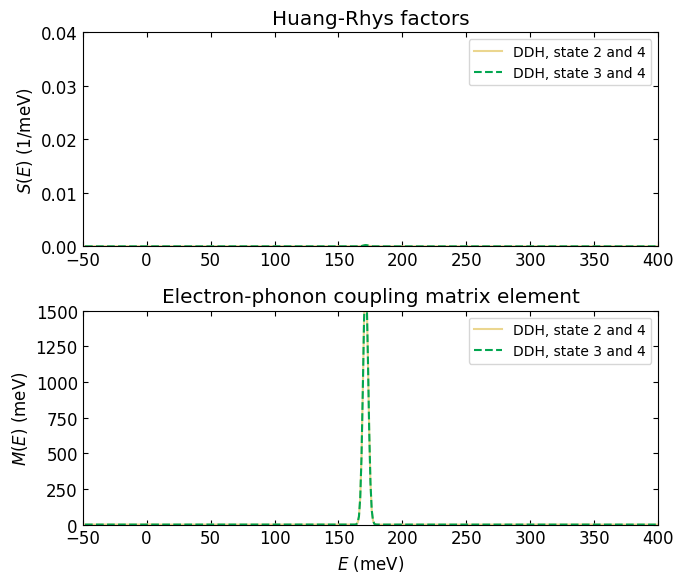

In [12]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [blue, red, goldenrod_yellow, emerald_green]

ax[0].plot(spectral_density_hrf_24_ddh[0], spectral_density_hrf_24_ddh[1],
            color=colors[2], linestyle='-', label=r'DDH, state 2 and 4')
ax[0].plot(spectral_density_hrf_34_ddh[0], spectral_density_hrf_34_ddh[1],
            color=colors[3], linestyle='--', label=r'DDH, state 3 and 4')

ax[1].plot(
    spectral_density_dH_dq_24_ddh[0],
    spectral_density_dH_dq_24_ddh[1],
    color=colors[2],
    label=r'DDH, state 2 and 4'
)
ax[1].plot(
    spectral_density_dH_dq_34_ddh[0],
    spectral_density_dH_dq_34_ddh[1],
    color=colors[3],
    label=r'DDH, state 3 and 4',
    linestyle='--'
)

ax[0].set_title('Huang-Rhys factors')
ax[1].set_title('Electron-phonon coupling matrix element')

for i in range(2):
    ax[i].legend(loc='upper right', fontsize=10)
    ax[1].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$S(E)$ (1/meV)')
    ax[1].set_ylabel('$M(E)$ (meV)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 0.04])
    ax[1].set_ylim([0, 1500])
    ax[i].set_xlim([-50, 400])

fig.tight_layout()
plt.show()

In [13]:
print(sum(dict_nonrad_24_ddh['hr_factors']))
indices = np.argsort(dict_nonrad_24_ddh['hr_factors'])
print('index     freq (meV)      hr_factor     1-2hr_factor')
for ind in indices[-1:-11:-1]:
    print('%4d    % 12.6f    % 10.6f    % 10.6f' % (
        ind, dict_nonrad_24_ddh['freqs'][ind] * hbar / eV * 1e3,
        dict_nonrad_24_ddh['hr_factors'][ind],
        1 - 2 * dict_nonrad_24_ddh['hr_factors'][ind]
        ))

0.0012266259406856564
index     freq (meV)      hr_factor     1-2hr_factor
 643      171.226975      0.001152      0.997697
 644      171.226975      0.000075      0.999850
 221      105.341307      0.000000      1.000000
 220      105.239092      0.000000      1.000000
 219      105.239092      0.000000      1.000000
 218      105.043801      0.000000      1.000000
 217      104.996049      0.000000      1.000000
 216      104.996049      0.000000      1.000000
 215      104.915799      0.000000      1.000000
 214      104.915799      0.000000      1.000000


It can be seen that the spectral density $M(E)$ computed between state 2, 4 and that between state 3, 4 are the same, and is dominated by a single peak at 170 meV, which is the localized vibrational mode around the NV center.

In [14]:
# check normalization
print(np.sum(spectral_density_dH_dq_24_ddh[1] * (spectral_density_dH_dq_24_ddh[0][1] - spectral_density_dH_dq_24_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(spectral_density_dH_dq_34_ddh[1] * (spectral_density_dH_dq_34_ddh[0][1] - spectral_density_dH_dq_34_ddh[0][0])) * 1e-3 * 1e-3 * constants.eV * constants.eV)
print(np.sum(dict_nonrad_24_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_24_ddh['freqs'])))
print(np.sum(dict_nonrad_34_ddh['dH_dq']**2 * constants.hbar / (2 * dict_nonrad_34_ddh['freqs'])))

2.2356268486854467e-40
2.2356993437352885e-40
2.2356268486854454e-40
2.235699343735288e-40


## 2. Compute nonradiative rate

We can compute the lineshape function for both the radiative and non-radiative transitions at different temperatures, with a broadening parameter provided for each temperature.

In [15]:
temperatures = np.array([4, 78])
zpl_broadenings = np.ones_like(temperatures)*0.18 # meV

rad_lineshapes_ddh = []
nonrad_lineshapes_ddh = []

for temp, zpl_broadening in zip(temperatures, zpl_broadenings):
    tmp = nonrad_24_ddh.compute_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    rad_lineshapes_ddh.append(tmp)
    print()

    tmp = nonrad_24_ddh.compute_nonrad_lineshape_fft(
        dict_nonrad_24_ddh,
        temp=temp,
        sigma=[6, 2],
        zpl_broadening=zpl_broadening,
        lineshape_energy_range=[-2000, 2000],
        lineshape_energy_resolution=40001
    )
    nonrad_lineshapes_ddh.append(tmp)
    print()

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981512

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 1.3953685263152534e-18

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 999.9999999981512

time_axis range: -2.0678338484646895e-11 to 2.0678338484646895e-11
d_t (s): 1.0338910769554208e-15
Energy range (meV): -1999.9999999973306 to 1999.9999999973306
d_E (meV): 0.09999999999968168
Integral check: 1.3953685263393693e-18



<>:38: SyntaxWarning: invalid escape sequence '\G'
<>:38: SyntaxWarning: invalid escape sequence '\G'
/tmp/ipykernel_849005/3175483154.py:38: SyntaxWarning: invalid escape sequence '\G'
  ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')
/tmp/ipykernel_849005/3175483154.py:43: UserWarning: Attempt to set non-positive ylim on a log-scaled axis will be ignored.
  ax[1].set_ylim([0, 1e15])


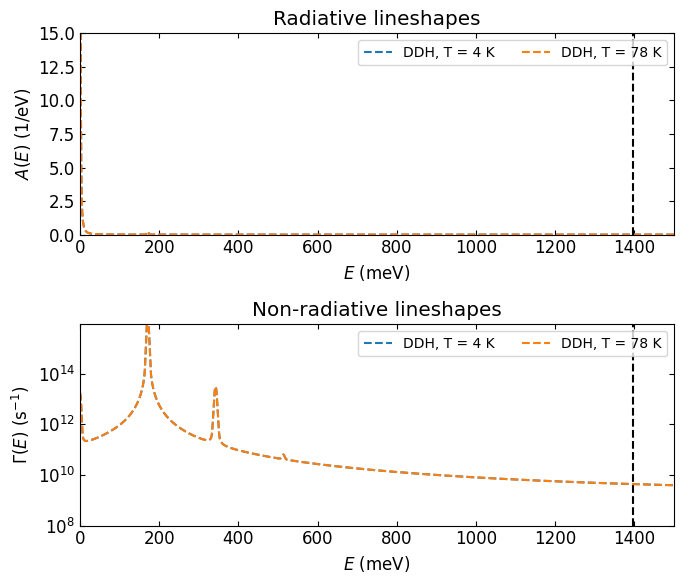

In [16]:
fig, ax = plt.subplots(2, 1, figsize=(7, 6))

colors = [deep_violet, soft_coral, emerald_green]

temperatures_to_plot = temperatures

for i, temp in enumerate(temperatures_to_plot):
    ax[0].plot(
        rad_lineshapes_ddh[i][0],
        rad_lineshapes_ddh[i][1],
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )

for i, temp in enumerate(temperatures_to_plot):
    ax[1].plot(
        nonrad_lineshapes_ddh[i][0],
        nonrad_lineshapes_ddh[i][1] * 2 * np.pi / hbar,
        linestyle='--',
        label='DDH, T = %.0f K' % (temp)
    )

# np.savez("NVD_singlets_locmode_T78K",
#          x=nonrad_lineshapes_ddh[i][0], 
#          y=nonrad_lineshapes_ddh[i][1]*2*np.pi/hbar
#         )

ax[0].axvline(x=adiabatic_energy_ddh, color='black', linestyle='--')
ax[1].axvline(x=adiabatic_energy_ddh, color='black', linestyle='--')

ax[0].set_title('Radiative lineshapes')
ax[1].set_title('Non-radiative lineshapes')

for i in range(2):
    ax[i].legend(loc='upper right', ncols=2, fontsize=10)
    ax[i].set_xlabel('$E$ (meV)')
    ax[0].set_ylabel('$A(E)$ (1/eV)')
    ax[1].set_ylabel('$\Gamma(E)$ (s$^{-1}$)')
    ax[i].tick_params(direction='in')
    ax[i].yaxis.set_ticks_position('both')
    ax[i].xaxis.set_ticks_position('both')
    ax[0].set_ylim([0, 15])
    ax[1].set_ylim([0, 1e15])
    ax[1].set_yscale('log')
    ax[1].set_ylim(bottom=1e+8,top=9e+15)
    ax[i].set_xlim([-0, 1500])

fig.tight_layout()
plt.show()

By comparing the radiative and non-radiative lineshapes, we can see that the non-radiative lineshape has a signature of right shifted by about 170 meV, originating from the strong nonadiabatic coupling associated with the 170 meV local phonon mode.

We can compute the nonradiative rate at the corresponding nonadiabatic transition energy.

In [17]:
print()
print('Nonradiative, all modes, DDH')
for i, temp in enumerate(temperatures):
    for energy, lineshape in zip(*nonrad_lineshapes_ddh[i]):
        if abs(energy - adiabatic_energy_ddh) < 0.01:
            print('T = %3.f K, Energy = %.12e meV, rate = %.12e 1/s' % (
                temp,energy, lineshape * 2 * np.pi / hbar)
            )


Nonradiative, all modes, DDH
T =   4 K, Energy = 1.396999999998e+03 meV, rate = 4.363720081638e+09 1/s
T =  78 K, Energy = 1.396999999998e+03 meV, rate = 4.363720081620e+09 1/s
